# Tutorial 4 — Generative modeling of AD progression

Use PIANO's decoder to simulate gene expression at specified Alzheimer's disease stages. The provided model was trained on SEA-AD middle temporal gyrus snRNA-seq with donor-level `Continuous Pseudo-progression Score (CPS)` (0 = before AD onset, 1 = late) and `Age at Death` as continuous covariates, plus `Donor ID` and `Sex` as categorical covariates.

`get_counterfactual(covariates={"Continuous Pseudo-progression Score": cps})` holds cell identity fixed and asks: *what would this cell express if it were at this disease stage?*

Nuclei are plotted at projected coordinates on one MERFISH section.

## Steps

1. Load the trained Composer and the Sst + L2/3 IT section file
2. Decode expression at CPS 0, 0.5, and 1
3. Plot MME in Sst and APP in L2/3 IT on the section

## Data

Download from [https://PLACEHOLDER_DATA_URL](https://PLACEHOLDER_DATA_URL) and point `DATA_DIR` at that folder:

- `adata_sec_SST_L2_3IT.h5ad` — Sst and L2/3 IT nuclei; `obsm["spatial_projected"]` and `obs["spatial_nn_subclass"]` are already set
- `pianist.pkl` — trained Composer
- `model_checkpoint.pt` — trained weights (the pickle stores settings only, not weights)

The full SEA-AD snRNA-seq and MERFISH objects used to train and project are too large to host. They are available on reasonable request. The last section shows how this subset and the vrun30 model were made.


## 1. Setup


In [1]:
# Google Colab only (skip on your own machine): install PIANO and mount Google Drive.
# Uncomment, run once, then point DATA_DIR / OUT_DIR below at your Drive folder.
# !pip install -q piano-integration
# from google.colab import drive
# drive.mount("/content/drive")

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # Needed for reproducible GPU training; set before importing piano
from piano import Composer
import warnings
warnings.filterwarnings("ignore")

# DATA_DIR = Path("data/generative_ad")  # folder with the downloaded h5ad, pianist.pkl, and checkpoint
DATA_DIR = Path("/jukebox/krienen/lab_members/annita/piano/results/generative_ad")
OUT_DIR = Path("../results/generative_ad")
# DATA_DIR = Path("/content/drive/MyDrive/piano_data/generative_ad")  # Google Colab
# OUT_DIR = Path("/content/drive/MyDrive/piano_results/generative_ad")  # Google Colab
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEC_H5AD = DATA_DIR / "adata_sec_SST_L2_3IT.h5ad"
PIANIST_PKL = DATA_DIR / "pianist.pkl"
CHECKPOINT = DATA_DIR / "model_checkpoint.pt"
CPS_VALUES = (0.0, 0.5, 1.0)



/jukebox/krienen/lab_members/annita/venvs/piano-integration/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the trained Composer


In [3]:
%%time
pianist = Composer.load(PIANIST_PKL, model_checkpoint_path=CHECKPOINT, device="cuda")
pianist.stratify_column = None  # vrun30 pickle predates stratified sampling



Preparing model with input size: 4251, distribution: nb, categorical_covariate_keys: ['Donor ID', 'Sex'], continuous_covariate_keys: ['Age at Death', 'Continuous Pseudo-progression Score'], adversarial: True
CPU times: user 181 ms, sys: 272 ms, total: 453 ms
Wall time: 464 ms


## 3. Load the section file

Sst and L2/3 IT only. Coordinates are in `obsm["spatial_projected"]` (kNN to MERFISH; see Tutorial 3).


In [4]:
adata = sc.read_h5ad(SEC_H5AD)
print(adata)
print(adata.obs["spatial_nn_subclass"].value_counts())



AnnData object with n_obs × n_vars = 30485 × 4251
    obs: 'sample_id', 'Neurotypical reference', 'Donor ID', 'Organism', 'Brain Region', 'Sex', 'Gender', 'Age at Death', 'Race (choice=White)', 'Race (choice=Black/ African American)', 'Race (choice=Asian)', 'Race (choice=American Indian/ Alaska Native)', 'Race (choice=Native Hawaiian or Pacific Islander)', 'Race (choice=Unknown or unreported)', 'Race (choice=Other)', 'specify other race', 'Hispanic/Latino', 'Highest level of education', 'Years of education', 'PMI', 'Fresh Brain Weight', 'Brain pH', 'Overall AD neuropathological Change', 'Thal', 'Braak', 'CERAD score', 'Overall CAA Score', 'Highest Lewy Body Disease', 'Total Microinfarcts (not observed grossly)', 'Total microinfarcts in screening sections', 'Atherosclerosis', 'Arteriolosclerosis', 'LATE', 'Cognitive Status', 'Last CASI Score', 'Interval from last CASI in months', 'Last MMSE Score', 'Interval from last MMSE in months', 'Last MOCA Score', 'Interval from last MOCA in month

## 4. Simulate expression at three CPS values

Each call returns a cells × genes count matrix for that disease stage. Donor, sex, and age stay as in the data.


In [5]:
%%time
for cps in CPS_VALUES:
    adata.layers[f"CF_CPS_{cps}"] = pianist.get_counterfactual(adata, covariates={"Continuous Pseudo-progression Score": cps})
    print(f"CPS {cps}:", adata.layers[f"CF_CPS_{cps}"].shape)

Note: 15102237 values in adata.X are not integers, so counts are stored as float32 (twice the memory of uint16). piano models raw counts: if adata.X was normalized by mistake, pass raw counts instead; if non-integer values are intended (e.g. TPM from SMART-seq), ignore this note


Retrieving counterfactual gene counts with shape (30485, 4251)


CPS 0.0: (30485, 4251)


Note: 15102237 values in adata.X are not integers, so counts are stored as float32 (twice the memory of uint16). piano models raw counts: if adata.X was normalized by mistake, pass raw counts instead; if non-integer values are intended (e.g. TPM from SMART-seq), ignore this note


Retrieving counterfactual gene counts with shape (30485, 4251)


CPS 0.5: (30485, 4251)


Note: 15102237 values in adata.X are not integers, so counts are stored as float32 (twice the memory of uint16). piano models raw counts: if adata.X was normalized by mistake, pass raw counts instead; if non-integer values are intended (e.g. TPM from SMART-seq), ignore this note


Retrieving counterfactual gene counts with shape (30485, 4251)


CPS 1.0: (30485, 4251)
CPU times: user 2.55 s, sys: 2.09 s, total: 4.64 s
Wall time: 5.23 s


## 5. Plot spatial maps

For each subclass/gene: absolute expression at CPS 0, then per-cell Δ at CPS 0.5 and 1.0 vs that baseline.


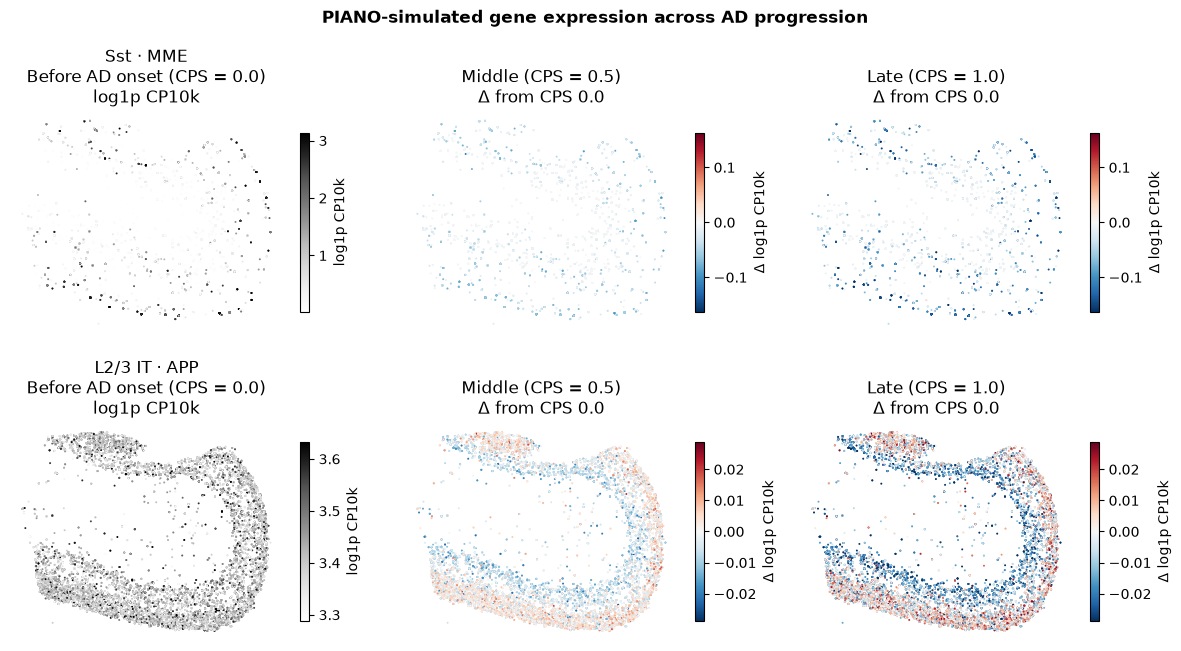

In [6]:
%matplotlib inline

def log1p_cp10k(mat, gene):
    x = np.asarray(mat[:, adata.var_names.get_loc(gene)]).ravel()
    lib = np.asarray(mat.sum(axis=1)).ravel()
    return np.log1p((x / (lib + 1e-8)) * 1e4)

rows = [("Sst", "MME"), ("L2/3 IT", "APP")]
panels = [
    (0.0, "Before AD onset", "raw"),
    (0.5, "Middle", "delta"),
    (1.0, "Late", "delta"),
]
ref_cps = 0.0

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for i, (subclass, gene) in enumerate(rows):
    mask = (adata.obs["spatial_nn_subclass"] == subclass).to_numpy()
    xy = adata.obsm["spatial_projected"][mask]
    ref = log1p_cp10k(adata.layers[f"CF_CPS_{ref_cps}"], gene)[mask]
    deltas = []
    vals = []
    for cps, _, mode in panels:
        v = log1p_cp10k(adata.layers[f"CF_CPS_{cps}"], gene)[mask]
        if mode == "delta":
            v = v - ref
            deltas.append(v)
        vals.append(v)
    dlim = np.quantile(np.abs(np.concatenate(deltas)), 0.98)

    for j, (ax, (cps, label, mode), v) in enumerate(zip(axes[i], panels, vals)):
        row_tag = f"{subclass} · {gene}\n" if j == 0 else ""
        if mode == "delta":
            sca = ax.scatter(xy[:, 0], xy[:, 1], c=v, cmap="RdBu_r",
                             vmin=-dlim, vmax=dlim, s=2, rasterized=True, linewidths=0)
            ax.set_title(f"{row_tag}{label} (CPS = {cps})\nΔ from CPS {ref_cps}")
            fig.colorbar(sca, ax=ax, shrink=0.6, label="Δ log1p CP10k")
        else:
            sca = ax.scatter(xy[:, 0], xy[:, 1], c=v, cmap="Greys",
                             vmin=np.quantile(v, 0.02), vmax=np.quantile(v, 0.98),
                             s=2, rasterized=True, linewidths=0)
            ax.set_title(f"{row_tag}{label} (CPS = {cps})\nlog1p CP10k")
            fig.colorbar(sca, ax=ax, shrink=0.6, label="log1p CP10k")
        ax.set_aspect("equal")
        ax.axis("off")

fig.suptitle("PIANO-simulated gene expression across AD progression", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "sst_mme_l23_app_cps.png", dpi=200, bbox_inches="tight")
plt.show()



## Optional: how these files were made

Steps for how we obtained the files and specifics on how the PIANO model was trained: train on SEA-AD MTG snRNA-seq, project nuclei onto one MERFISH section, keep Sst and L2/3 IT.

The full snRNA-seq, MERFISH, and integrated objects are too large to host. They are available on reasonable request.


In [ ]:
import pandas as pd
# Paths to the full objects (not in the tutorial download; available on request)
TRAIN_H5AD = Path("/path/to/SEAAD_MTG_RNAseq_hvg4096_plus_spatial_plus_seaad_markers.h5ad")
MERFISH_H5AD = Path("/path/to/SEAAD_MTG_MERFISH.h5ad")
INTEGRATED_H5AD = Path("/path/to/adata_integrated.h5ad")  # vrun30 output, all nuclei
# KNN-mapped scRNA from class-wise sc+spatial integrations (Glut / GABA / NN)
KNN_PATHS = {
    "Glut": Path("/path/to/adata_integrated_knn_mapped_Glut.h5ad"),
    "GABA": Path("/path/to/adata_integrated_knn_mapped_GABA.h5ad"),
    "NN": Path("/path/to/adata_integrated_knn_mapped_NN.h5ad"),
}
SECTION = "H21.33.031.CX24.MTG.02.007.1.01.01"
SPATIAL_Y_CLIP = 3500
SUBCLASSES = ["Sst", "L2/3 IT"]

# --- 1. Train (vrun30) ---
# Input already contains HVGs plus extra spatial/marker genes; n_top_genes=-1 keeps that set.
# Age at Death is z-scored in the object; CPS is left on [0, 1].
adata_train = sc.read_h5ad(TRAIN_H5AD)
pianist = Composer(
    adata=adata_train,
    categorical_covariate_keys=["Donor ID", "Sex"],
    continuous_covariate_keys=["Age at Death", "Continuous Pseudo-progression Score"],
    n_top_genes=-1,
    memory_mode="CPU",
    compile_model=True,
    adversarial=True,
    max_epochs=200,
    min_kld_weight=0.0,
    max_kld_weight=0.25,
    random_seed=0,
    run_name="run30_add_genes_piano",
    outdir=str(OUT_DIR),
)
pianist.run_pipeline()

# --- 2. Project scRNA onto one MERFISH section ---
# Each nucleus finds its nearest MERFISH cell in PIANO latent space (Tutorial 3 / KNN_transfer.py).
# That neighbor's Subclass and (x, y) become spatial_nn_subclass and spatial_projected.
merfish = sc.read_h5ad(MERFISH_H5AD)
sec_mask = merfish.obs["Section"] == SECTION
sec_obs = merfish.obs[sec_mask].copy()
sec_obs["x"] = merfish.obsm["spatial"][sec_mask, 0]
sec_obs["y"] = merfish.obsm["spatial"][sec_mask, 1]
sec_obs = sec_obs[sec_obs["y"] > SPATIAL_Y_CLIP]
sec_barcodes = set(sec_obs.index)

knn_list = []
for name, path in KNN_PATHS.items():
    obs = sc.read_h5ad(path).obs.copy()
    obs["spatial_nn_barcode_clean"] = obs["spatial_nn_barcode"].str.replace("-spatial$", "", regex=True)
    obs["knn_object"] = name
    knn_list.append(obs)
knn = pd.concat(knn_list)
knn.index = knn.index.str.replace("-scRNA$", "", regex=True)

adata_int = sc.read_h5ad(INTEGRATED_H5AD)
shared = knn.index.intersection(adata_int.obs_names)
adata_sec = adata_int[shared].copy()
knn = knn.loc[shared]
adata_sec.obs["spatial_nn_subclass"] = knn["spatial_nn_subclass"].values

# Keep nuclei whose MERFISH neighbor sits on this section; copy that neighbor's coordinates
on_sec = knn.index[knn["spatial_nn_barcode_clean"].isin(sec_barcodes)]
on_sec = on_sec[on_sec.isin(adata_sec.obs_names)]
adata_sec = adata_sec[on_sec].copy()
knn_sec = knn.loc[on_sec].join(sec_obs[["x", "y"]], on="spatial_nn_barcode_clean", how="left")
knn_sec = knn_sec.dropna(subset=["x", "y"])
adata_sec = adata_sec[knn_sec.index].copy()
adata_sec.obsm["spatial_projected"] = np.column_stack([knn_sec["x"].values, knn_sec["y"].values])

# --- 3. Keep Sst and L2/3 IT ---
adata_sec = adata_sec[adata_sec.obs["spatial_nn_subclass"].isin(SUBCLASSES)].copy()
adata_sec.write_h5ad(DATA_DIR / "adata_sec_SST_L2_3IT.h5ad")
print(adata_sec)
print(adata_sec.obs["spatial_nn_subclass"].value_counts())

